# ECE 3715 Mini-Project 1: Steps 6–8

**Team 1** · ECE 3715, Fall 2026 · Dr. Nir Regev

A wireless link sends 1000-bit packets. Each bit is corrupted independently with probability $p$, and every corrupted packet is retransmitted until one gets through. These steps count the retransmissions, measure how fast simulated averages settle, and combine everything into the throughput of the link.

| Step | Topic |
|---|---|
| 6 | Retransmissions and the geometric distribution |
| 7 | Expectation, variance, and how fast estimates settle |
| 8 | The throughput of the link |

Run with **Kernel → Restart Kernel and Run All Cells**. The functions live in `mp1lib.py`. The notebook is seeded once with `SEED = 1` (the team number), and every number quoted in the text comes from a clean top-to-bottom run. A summary of the check-yourself values is at the end.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

from mp1lib import packet_errors, attempts_until_clean

start_time = time.perf_counter()

SEED = 1                              # team number
rng = np.random.default_rng(SEED)     # the only seeded generator in the notebook

# One independent generator per step, created once, in step order (Steps 1-8), so
# re-running one step's cells never shifts another step's random numbers.
# Steps 6, 7 and 8 use rng6, rng7 and rng8.
rng1, rng2, rng3, rng4, rng5, rng6, rng7, rng8 = [rng.spawn(1)[0] for _ in range(8)]

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})
Z95 = stats.norm.ppf(0.975)           # 1.96: a 95% interval is +/- 1.96 standard errors

## Helpers

Every comparison between simulation and theory reports the difference, its standard error (SE), and $|z| = |\text{difference}|\,/\,\text{SE}$. A $|z|$ below 3 means the difference is within three standard errors.

In [2]:
def mean_and_se(x):
    """Sample mean of x and its standard error, s / sqrt(N)."""
    x = np.asarray(x, dtype=float)
    return x.mean(), x.std(ddof=1) / np.sqrt(len(x))


def var_and_se(x):
    """Sample variance of x and its standard error, sqrt((m4 - s^4) / N),
    where m4 is the fourth central moment."""
    x = np.asarray(x, dtype=float)
    s2 = x.var(ddof=1)
    m4 = np.mean((x - x.mean()) ** 4)
    return s2, np.sqrt((m4 - s2**2) / len(x))


def prob_and_se(count, n):
    """Estimated probability count / n and its standard error, sqrt(p (1 - p) / n)."""
    p = count / n
    return p, np.sqrt(p * (1 - p) / n)


def show_table(headers, rows):
    """Display a table. Each row is a list of already-formatted strings."""
    def cell(text):
        return str(text).replace("|", "\\|")    # a bare | would be read as a column divider
    lines = ["| " + " | ".join(cell(h) for h in headers) + " |",
             "|" + "|".join([":---"] + ["---:"] * (len(headers) - 1)) + "|"]
    for row in rows:
        lines.append("| " + " | ".join(cell(x) for x in row) + " |")
    display(Markdown("\n".join(lines)))


def report_largest_z(z_values):
    """Print the largest |z| in a set of comparisons and whether all are within 3 SE."""
    z_max = max(z_values)
    print(f"Largest |z| = {z_max:.2f}  ->  all within 3 standard errors: {z_max < 3}")

## Step 6: Retransmissions and the geometric distribution

### 6.1 Why the number of attempts is geometric

When an attempt is made, we are basically creating a Bernoulli trial that delivers a packet with probability $q$. The attempts are independent from one another with the same $q$ because every retransmission gets new, independent bit errors from the channel. The number of attempts until the first success in independent, identical Bernoulli trials is geometric, since $T = k$ means $k-1$ failures followed by one success.

### 6.2 Convention: count attempts, starting at 1

$T$ is the number of **attempts**, including the successful one, so $T \in \{1, 2, 3, \dots\}$. The other common convention counts failures before the first success, $Y = T - 1$, which starts at 0. The two have different pmfs and means that differ by exactly 1, so mixing them up is the most common error in this step.

| convention | values | pmf | mean | variance |
|---|---|---|---|---|
| attempts $T$ (used here) | $1, 2, 3, \dots$ | $(1-q)^{k-1}\,q$ | $1/q$ | $(1-q)/q^2$ |
| failures $Y = T - 1$ | $0, 1, 2, \dots$ | $(1-q)^{k}\,q$ | $(1-q)/q$ | $(1-q)/q^2$ |

At $q = 0.7$: $E[T] = 1/0.7 = 1.4286$ and $\operatorname{Var}(T) = 0.3/0.49 = 0.6122$.

**Tail probability.** $T > k$ means the first $k$ attempts all failed, so $P(T > k) = (1-q)^k$.

**Mean.** By the tail-sum formula,

$$E[T] = \sum_{k=0}^{\infty} P(T > k) = \sum_{k=0}^{\infty} (1-q)^k = \frac{1}{1-(1-q)} = \frac{1}{q}.$$

**Variance.** Differentiating the geometric series twice gives $\sum_{k \ge 2} k(k-1)\,x^{k-2} = \dfrac{2}{(1-x)^3}$. With $x = 1-q$:

$$E[T(T-1)] = q(1-q)\sum_{k\ge 2} k(k-1)(1-q)^{k-2} = q(1-q)\cdot\frac{2}{q^3} = \frac{2(1-q)}{q^2},$$

$$\operatorname{Var}(T) = E[T(T-1)] + E[T] - E[T]^2 = \frac{2(1-q)}{q^2} + \frac{1}{q} - \frac{1}{q^2} = \frac{1-q}{q^2}.$$

**Library conventions.** `attempts_until_clean` draws with NumPy's `Generator.geometric`, and the pmf overlay uses `scipy.stats.geom`. Both count attempts starting at 1. The next cell checks this and runs the required hand-checkable test.

In [3]:
# Required hand-checkable test: on a perfect channel (q = 1) every packet gets
# through on the first attempt, so all 1000 counts must equal 1.
test_counts = attempts_until_clean(1000, 1.0, rng6)
assert np.all(test_counts == 1)
print("Test passed: attempts_until_clean(1000, q=1.0) returned all ones")

# scipy.stats.geom counts attempts too: P(T = 0) is 0 and the mean is 1/q.
q6 = 0.7                              # per-attempt clean probability, for Step 6 only
print(f"scipy.stats.geom: P(T=0) = {stats.geom.pmf(0, q6):.2f}, P(T=1) = {stats.geom.pmf(1, q6):.2f}, "
      f"mean = {stats.geom.mean(q6):.4f} (1/q = {1 / q6:.4f})")

Test passed: attempts_until_clean(1000, q=1.0) returned all ones
scipy.stats.geom: P(T=0) = 0.00, P(T=1) = 0.70, mean = 1.4286 (1/q = 1.4286)


### 6.3 Simulate 100,000 retransmission sequences

For this step only, the per-attempt clean probability is $q = 0.7$, a round number that makes the histogram easy to read. Step 8 uses the real $q$ for the link.

The histogram uses `density=True` with bins one unit wide, so each bar is the fraction of sequences that needed exactly $k$ attempts. The table compares those fractions with the pmf for $k = 1$ to $6$; beyond that there are too few samples for a useful comparison.

In [4]:
N6 = 100_000
attempts6 = attempts_until_clean(N6, q6, rng6)
print(f"{N6:,} sequences simulated. Fewest attempts: {attempts6.min()}, most: {attempts6.max()}")

counts = np.bincount(attempts6, minlength=7)      # counts[k] = sequences that needed exactly k attempts
rows, z_values = [], []
for k in range(1, 7):
    simulated = counts[k] / N6
    exact = stats.geom.pmf(k, q6)
    se = np.sqrt(exact * (1 - exact) / N6)
    z_values.append(abs(simulated - exact) / se)
    rows.append([str(k), f"{simulated:.5f}", f"{exact:.5f}", f"{simulated - exact:+.1e}",
                 f"{se:.1e}", f"{z_values[-1]:.2f}"])

show_table(["k", "simulated", "geometric pmf", "difference", "SE", "|z|"], rows)
report_largest_z(z_values)

100,000 sequences simulated. Fewest attempts: 1, most: 10


| k | simulated | geometric pmf | difference | SE | \|z\| |
|:---|---:|---:|---:|---:|---:|
| 1 | 0.69832 | 0.70000 | -1.7e-03 | 1.4e-03 | 1.16 |
| 2 | 0.21111 | 0.21000 | +1.1e-03 | 1.3e-03 | 0.86 |
| 3 | 0.06278 | 0.06300 | -2.2e-04 | 7.7e-04 | 0.29 |
| 4 | 0.01933 | 0.01890 | +4.3e-04 | 4.3e-04 | 1.00 |
| 5 | 0.00570 | 0.00567 | +3.0e-05 | 2.4e-04 | 0.13 |
| 6 | 0.00182 | 0.00170 | +1.2e-04 | 1.3e-04 | 0.91 |

Largest |z| = 1.16  ->  all within 3 standard errors: True


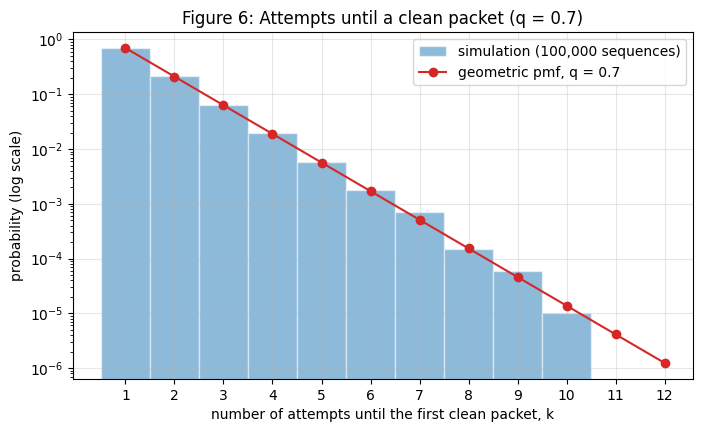

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))

# Histogram as a density, with unit-width bins centred on each integer k
bins = np.arange(0.5, attempts6.max() + 1.5)
ax.hist(attempts6, bins=bins, density=True, log=True, color="C0", alpha=0.5,
        edgecolor="white", label=f"simulation ({N6:,} sequences)")

# Exact geometric pmf
k_values = np.arange(1, attempts6.max() + 3)
ax.plot(k_values, stats.geom.pmf(k_values, q6), "o-", color="C3", label="geometric pmf, q = 0.7")

ax.set_xticks(k_values)
ax.set_xlabel("number of attempts until the first clean packet, k")
ax.set_ylabel("probability (log scale)")
ax.set_title("Figure 6: Attempts until a clean packet (q = 0.7)")
ax.legend()
plt.show()

**What Figure 6 shows.** The simulated bars sit on the geometric pmf. On the log axis the pmf is a straight line, because each extra attempt multiplies the probability by $1 - q = 0.3$, a drop of about half a decade per attempt. The table confirms the match: for $k = 1$ to $6$, the largest difference between simulation and pmf is 1.16 standard errors. The bars at the far right are ragged only because so few sequences reach them: about 5 of the 100,000 sequences need 9 attempts, so those bars carry roughly ±45% sampling noise, which the log axis exaggerates. Even with a 70% success rate per attempt, $0.3^3 = 2.7\%$ of packets need four or more attempts.

### 6.4 Sample mean and variance against the closed forms

The closed forms for the attempts convention are $E[T] = 1/q$ and $\operatorname{Var}(T) = (1-q)/q^2$.

In [6]:
mean_exact = 1 / q6
var_exact = (1 - q6) / q6**2
mean_sim, mean_sim_se = mean_and_se(attempts6)
var_sim, var_sim_se = var_and_se(attempts6)

rows = [
    ["mean", f"{mean_sim:.4f}", f"1/q = {mean_exact:.4f}", f"{mean_sim - mean_exact:+.4f}",
     f"{mean_sim_se:.4f}", f"{abs(mean_sim - mean_exact) / mean_sim_se:.2f}"],
    ["variance", f"{var_sim:.4f}", f"(1-q)/q² = {var_exact:.4f}", f"{var_sim - var_exact:+.4f}",
     f"{var_sim_se:.4f}", f"{abs(var_sim - var_exact) / var_sim_se:.2f}"],
]
show_table(["quantity", "simulated", "closed form", "difference", "SE", "|z|"], rows)

| quantity | simulated | closed form | difference | SE | \|z\| |
|:---|---:|---:|---:|---:|---:|
| mean | 1.4325 | 1/q = 1.4286 | +0.0039 | 0.0025 | 1.57 |
| variance | 0.6238 | (1-q)/q² = 0.6122 | +0.0115 | 0.0062 | 1.87 |

**Result.** The sample mean is 1.4325 against $1/q = 1.4286$, a difference of +0.0039 with a standard error of 0.0025 ($|z| = $ 1.57). The sample variance is 0.6238 against $(1-q)/q^2 = 0.6122$, a difference of +0.0115 with a standard error of 0.0062 ($|z| = $ 1.87). Both closed forms are confirmed, which reproduces the check-yourself values 1.4286 and 0.6122.

### 6.5 The memoryless property

If a packet has already failed $m$ times, the chance it needs more than $n$ further attempts is the same as for a brand-new packet:

$$P(T > m+n \mid T > m) = \frac{P(T > m+n)}{P(T > m)} = \frac{(1-q)^{m+n}}{(1-q)^{m}} = (1-q)^{n} = P(T > n).$$

With $n = 2$ the exact value is $0.3^2 = 0.09$. The estimates below reuse the 100,000 sequences from 6.3.

In [7]:
n = 2
p_more_than_n, se_n = prob_and_se(np.sum(attempts6 > n), N6)
print(f"P(T > {n}) = {p_more_than_n:.4f} (SE {se_n:.4f});  exact value (1 - q)^{n} = {(1 - q6) ** n:.4f}")

rows, z_values = [], []
for m in (1, 3, 5):
    already_failed = attempts6[attempts6 > m]          # sequences whose first m attempts all failed
    p_cond, se_cond = prob_and_se(np.sum(already_failed > m + n), len(already_failed))
    diff = p_cond - p_more_than_n
    se_diff = np.sqrt(se_cond**2 + se_n**2)            # approximate: the two estimates share some samples
    z_values.append(abs(diff) / se_diff)
    rows.append([f"({m}, {n})", f"{len(already_failed):,}", f"{p_cond:.4f}", f"{se_cond:.4f}",
                 f"{diff:+.4f}", f"{se_diff:.4f}", f"{z_values[-1]:.2f}"])

show_table(["(m, n)", "sequences with T > m", "P(T > m+n | T > m)", "SE",
            "difference from P(T > n)", "SE of difference", "|z|"], rows)
report_largest_z(z_values)

P(T > 2) = 0.0906 (SE 0.0009);  exact value (1 - q)^2 = 0.0900


| (m, n) | sequences with T > m | P(T > m+n \| T > m) | SE | difference from P(T > n) | SE of difference | \|z\| |
|:---|---:|---:|---:|---:|---:|---:|
| (1, 2) | 30,168 | 0.0921 | 0.0017 | +0.0015 | 0.0019 | 0.82 |
| (3, 2) | 2,779 | 0.0993 | 0.0057 | +0.0087 | 0.0057 | 1.52 |
| (5, 2) | 276 | 0.0797 | 0.0163 | -0.0109 | 0.0163 | 0.67 |

Largest |z| = 1.52  ->  all within 3 standard errors: True


**Result.** All three conditional probabilities match $P(T > 2)$, with differences of 0.82, 1.52 and 0.67 standard errors for $m = 1$, 3 and 5. The standard error grows with $m$ because conditioning on $T > m$ keeps only a fraction $0.3^m$ of the sequences: 30,168 sequences for $m = 1$, but only 276 for $m = 5$. The $(5, 2)$ check is therefore about ten times noisier than the $(1, 2)$ check. That is the price of conditioning on a rare event, not a failure of memorylessness.

### 6.6 Why five failures don't change the odds of the sixth attempt

In the model, every attempt is a fresh, independent pass through a channel with the same $p$, so the sixth attempt succeeds with probability $q$ exactly like the first, and the five failures carry no information about it. The assumption doing the work is that the channel is independent and identically distributed from one attempt to the next; on a real radio link, fading, shadowing and interference stay correlated over the channel's coherence time, so a run of failures means the link is probably in a bad state right now and an immediate retry is *less* likely to succeed, which is why practical retransmission schemes back off or change frequency before retrying.

## Step 7: Expectation, variance, and how fast estimates settle

This step measures how quickly a running average settles on the true mean. It uses one case from Step 4 and one from Step 6, and repeats each experiment 200 times.

| case | what is counted | mean $\mu$ | variance $\sigma^2$ | $\sigma$ |
|---|---|---|---|---|
| Binomial (Step 4) | bit errors in a 1000-bit packet, $p = 0.005$ | $np = 5$ | $np(1-p) = 4.975$ | 2.2305 |
| Geometric (Step 6) | attempts until a clean packet, $q = 0.7$ | $1/q = 1.4286$ | $(1-q)/q^2 = 0.6122$ | 0.7825 |

**What theory predicts.** The running mean after $N$ trials is $\bar X_N = \frac{1}{N}\sum_{i=1}^{N} X_i$. Because the trials are independent, their variances add:

$$\operatorname{Var}(\bar X_N) = \frac{1}{N^2}\sum_{i=1}^{N}\operatorname{Var}(X_i) = \frac{\sigma^2}{N}, \qquad \operatorname{SD}(\bar X_N) = \frac{\sigma}{\sqrt N}.$$

So the spread across runs should shrink like $1/\sqrt N$: ten times more trials gives only about three times ($\sqrt{10}$) the precision. By the central limit theorem, about 95% of runs should land within $\mu \pm 1.96\,\sigma/\sqrt N$.

**How the runs are stored.** Each run draws $10^5$ samples, records the running mean at 30 checkpoints, and discards the samples. Each case therefore stores a $200 \times 30$ array, never $200 \times 10^5$.

In [8]:
N_RUNS = 200
checkpoints = np.unique(np.round(np.logspace(1, 5, 30)).astype(int))   # 30 values of N, from 10 to 100,000


def running_means(draw):
    """Repeat an experiment N_RUNS times and return the running mean at each checkpoint.

    draw(n) must return n fresh samples. Each run keeps only its 30 checkpoint
    values, so the result has shape (N_RUNS, 30), not (N_RUNS, 100000).
    """
    result = np.empty((N_RUNS, len(checkpoints)))
    for run in range(N_RUNS):
        samples = draw(checkpoints[-1])                # 100,000 fresh samples for this run
        running_sum = np.cumsum(samples)
        result[run] = running_sum[checkpoints - 1] / checkpoints
    return result                                      # the samples are discarded here


def draw_binomial(n):
    """Bit errors in each of n packets of 1000 bits, p = 0.005 (Step 4)."""
    return packet_errors(n, 1000, 0.005, rng7)


def draw_geometric(n):
    """Attempts until a clean packet, for n packets with q = 0.7 (Step 6)."""
    return attempts_until_clean(n, 0.7, rng7)


t0 = time.perf_counter()
binomial_runs = running_means(draw_binomial)
geometric_runs = running_means(draw_geometric)
print(f"Stored array per case: {binomial_runs.shape}   (both cases took {time.perf_counter() - t0:.1f} s)")

Stored array per case: (200, 30)   (both cases took 1.3 s)


### 7.3–7.4 Spread of the 200 runs and the $1/\sqrt N$ curve

The shaded band in Figure 7 holds the central 95% of the 200 running means at each checkpoint. Two numbers test whether it follows $1/\sqrt N$:

- the slope of the band's half-width against $N$ on log-log axes, which should be $-0.5$;
- the constant $k$ in "half-width $= k/\sqrt N$", matched to the band at one checkpoint (the one nearest $N = 1000$), which the CLT says should be $1.96\,\sigma$.

In [9]:
def band_95(runs):
    """Central 95% of the runs at each checkpoint: returns (lower edge, upper edge, half-width).
    method="median_unbiased" avoids the slight inward bias numpy's default
    percentile has when there are only 200 runs."""
    lower, upper = np.percentile(runs, [2.5, 97.5], axis=0, method="median_unbiased")
    return lower, upper, (upper - lower) / 2


anchor = np.argmin(np.abs(np.log(checkpoints / 1000)))     # index of the checkpoint nearest N = 1000

cases = {
    #             runs            true mean  true sigma
    "Binomial":  (binomial_runs,  5.0,       np.sqrt(4.975)),
    "Geometric": (geometric_runs, 1 / 0.7,   np.sqrt(0.3 / 0.7**2)),
}

bands = {}
shape_rows, final_rows = [], []
for name, (runs, mu, sigma) in cases.items():
    lower, upper, half = band_95(runs)
    slope = np.polyfit(np.log(checkpoints), np.log(half), 1)[0]      # should be -0.5
    k_matched = half[anchor] * np.sqrt(checkpoints[anchor])           # half-width = k / sqrt(N) at the anchor
    final_mean, final_se = mean_and_se(runs[:, -1])                   # the 200 estimates at N = 100,000
    bands[name] = dict(runs=runs, mu=mu, sigma=sigma, lower=lower, upper=upper, half=half, k=k_matched)

    shape_rows.append([name, f"{slope:+.3f}", f"{k_matched:.3f}", f"{Z95 * sigma:.3f}",
                       f"{100 * (k_matched / (Z95 * sigma) - 1):+.1f}%"])
    final_rows.append([name, f"{final_mean:.4f}", f"{mu:.4f}", f"{final_mean - mu:+.1e}",
                       f"{final_se:.1e}", f"{abs(final_mean - mu) / final_se:.2f}"])

show_table(["case", "log-log slope (theory: −0.5)", f"k matched at N = {checkpoints[anchor]:,}",
            "CLT: k = 1.96σ", "k vs CLT"], shape_rows)
show_table(["case", "mean of the 200 runs at N = 10⁵", "true mean", "difference", "SE", "|z|"], final_rows)

| case | log-log slope (theory: −0.5) | k matched at N = 1,172 | CLT: k = 1.96σ | k vs CLT |
|:---|---:|---:|---:|---:|
| Binomial | -0.491 | 4.317 | 4.372 | -1.2% |
| Geometric | -0.495 | 1.567 | 1.534 | +2.2% |

| case | mean of the 200 runs at N = 10⁵ | true mean | difference | SE | \|z\| |
|:---|---:|---:|---:|---:|---:|
| Binomial | 5.0003 | 5.0000 | +2.6e-04 | 5.3e-04 | 0.49 |
| Geometric | 1.4284 | 1.4286 | -1.8e-04 | 1.8e-04 | 1.05 |

In [10]:
# 7.5: how many trials until the Binomial running mean is within 1% of the true mean in 95% of runs?
binom = bands["Binomial"]
tolerance = 0.01 * binom["mu"]                        # 1% of 5 = 0.05 errors per packet

last_wider = np.nonzero(binom["half"] > tolerance)[0][-1]    # last checkpoint where the band is wider than ±1%
N_lo, N_hi = checkpoints[last_wider], checkpoints[last_wider + 1]
h_lo, h_hi = binom["half"][last_wider], binom["half"][last_wider + 1]

# Straight-line interpolation on log-log axes between those two checkpoints
fraction = np.log(h_lo / tolerance) / np.log(h_lo / h_hi)
N_needed = N_lo * (N_hi / N_lo) ** fraction
N_clt = (Z95 * binom["sigma"] / tolerance) ** 2       # CLT: 1.96 sigma / sqrt(N) = 0.01 mu

print(f"Band is wider than ±1% at N = {N_lo:,} and narrower from N = {N_hi:,} on")
print(f"Interpolated crossing: N ≈ {N_needed:,.0f}   (CLT prediction: {N_clt:,.0f})")

Band is wider than ±1% at N = 5,736 and narrower from N = 7,880 on
Interpolated crossing: N ≈ 6,704   (CLT prediction: 7,645)


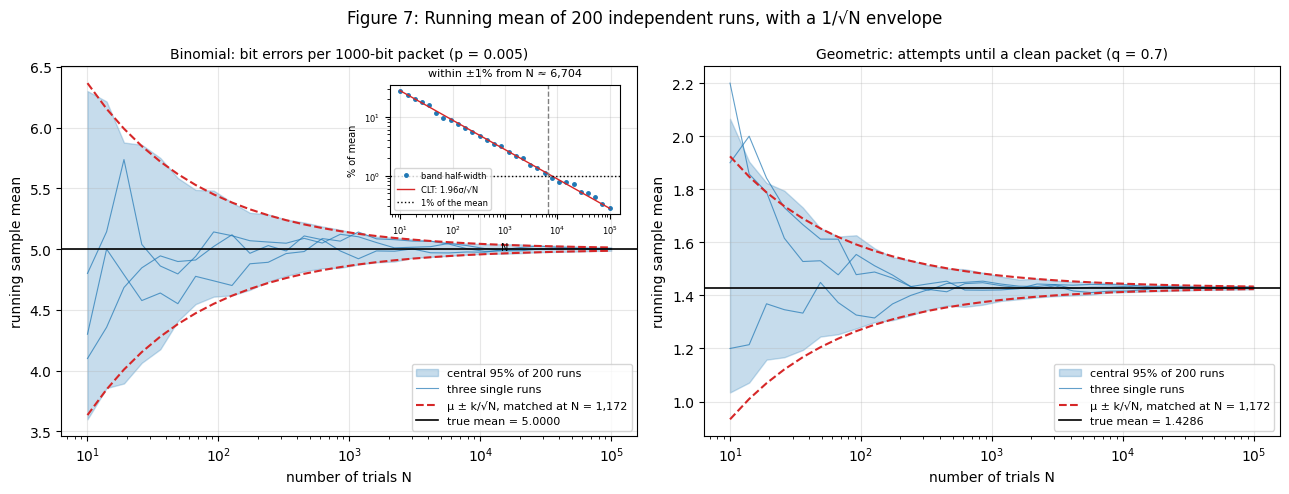

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, name in zip(axes, ["Binomial", "Geometric"]):
    b = bands[name]
    envelope = b["k"] / np.sqrt(checkpoints)

    ax.fill_between(checkpoints, b["lower"], b["upper"], color="C0", alpha=0.25,
                    label="central 95% of 200 runs")
    for run in range(3):                               # a few single runs for reference
        ax.plot(checkpoints, b["runs"][run], color="C0", lw=0.8, alpha=0.7,
                label="three single runs" if run == 0 else None)
    ax.plot(checkpoints, b["mu"] + envelope, "--", color="C3",
            label=f"μ ± k/√N, matched at N = {checkpoints[anchor]:,}")
    ax.plot(checkpoints, b["mu"] - envelope, "--", color="C3")
    ax.axhline(b["mu"], color="k", lw=1.2, label=f"true mean = {b['mu']:.4f}")

    ax.set_xscale("log")
    ax.set_xlabel("number of trials N")
    ax.set_ylabel("running sample mean")
    ax.legend(loc="lower right", fontsize=8)

axes[0].set_title("Binomial: bit errors per 1000-bit packet (p = 0.005)", fontsize=10)
axes[1].set_title("Geometric: attempts until a clean packet (q = 0.7)", fontsize=10)

# Inset on the Binomial panel: band half-width as a percentage of the mean, against the 1% target
inset = axes[0].inset_axes([0.57, 0.6, 0.4, 0.35])
inset.loglog(checkpoints, 100 * binom["half"] / binom["mu"], "o", ms=2.5, label="band half-width")
inset.loglog(checkpoints, 100 * Z95 * binom["sigma"] / np.sqrt(checkpoints) / binom["mu"],
             color="C3", lw=1, label="CLT: 1.96σ/√N")
inset.axhline(1, color="k", ls=":", lw=1, label="1% of the mean")
inset.axvline(N_needed, color="gray", ls="--", lw=1)
inset.set_title(f"within ±1% from N ≈ {N_needed:,.0f}", fontsize=8)
inset.set_xlabel("N", fontsize=7)
inset.set_ylabel("% of mean", fontsize=7)
inset.tick_params(labelsize=6)
inset.legend(fontsize=6, loc="lower left")

fig.suptitle("Figure 7: Running mean of 200 independent runs, with a 1/√N envelope")
fig.tight_layout()
plt.show()

**What Figure 7 shows.** In both panels, single runs wander for the first few hundred trials and then settle, while the shaded band holding the central 95% of the 200 runs narrows toward the true mean.

**7.4 Does the spread follow $1/\sqrt N$?** Yes. On log-log axes the band's half-width falls with a slope of -0.491 for the Binomial case and -0.495 for the geometric case, against $-0.5$ for $1/\sqrt N$. The dashed curve, scaled to match the band at $N = 1{,}172$, tracks the band across four decades of $N$, and its constant $k$ is 4.317 for the Binomial case and 1.567 for the geometric case, against the CLT values $1.96\,\sigma = 4.372$ and $1.534$ (-1.2% and +2.2%). The band itself is estimated from only 200 runs, so it wobbles by several percent from checkpoint to checkpoint, and small gaps between it and the dashed curve are expected. In practical terms, every extra decimal digit of accuracy costs 100 times more trials. The geometric band is lopsided at small $N$, reaching farther above the mean than below, because the geometric distribution is skewed to the right; that skew fades like $1/\sqrt N$, so after a few hundred trials the band is symmetric.

### 7.5 How many trials for 1% accuracy?

For the Binomial case, 1% of the mean is $\pm 0.05$ errors per packet. The inset in Figure 7 plots the band's half-width as a percentage of the mean. It is still wider than 1% at $N = $ 5,736 and narrower from $N = $ 7,880 on, and interpolating between those two checkpoints puts the crossing at $N \approx$ 6,704. The CLT gives a prediction to compare against:

$$1.96\,\frac{\sigma}{\sqrt N} \le 0.01\,\mu \quad\Longrightarrow\quad N \ge \left(\frac{1.96 \times 2.2305}{0.05}\right)^2 \approx 7{,}645.$$

The two agree to within about 12%. That is the size of error to expect here: the required $N$ scales with the square of the band's width, so the few-percent uncertainty of a band built from only 200 runs roughly doubles in $N$.

**Answer:** about 8,000 trials. The band is inside $\pm 1\%$ by $N = $ 7,880, and the CLT puts the requirement at about 7,600, so roughly 8,000 trials (order $10^4$) give the sample mean of the Binomial case a 95% chance of being within 1% of the true mean. Step 4's run of $10^5$ packets is well past that, with a 95% band of about $\pm 0.3\%$.

## Step 8: Throughput of the link

### 8.1 Probability that a packet arrives clean

The number of bit errors in an $n$-bit packet is $K \sim \text{Binomial}(n, p)$ (Step 4). A packet is clean when $K = 0$:

$$q(p) = P(K = 0) = \binom{n}{0}\,p^0\,(1-p)^{n} = (1-p)^{n}, \qquad n = 1000.$$

### 8.2 Expected transmissions per delivered packet

Attempts are independent and each one is clean with probability $q(p)$, so the number of transmissions is geometric (Step 6), and

$$E[T] = \frac{1}{q(p)} = (1-p)^{-n}.$$

In [12]:
N_BITS = 1000


def p_clean(p, n=N_BITS):
    """Probability that an n-bit packet has no bit errors: (1 - p)^n."""
    return (1 - np.asarray(p, dtype=float)) ** n


def expected_tx(p, n=N_BITS):
    """Expected transmissions per delivered packet: 1 / (1 - p)^n."""
    return 1 / p_clean(p, n)


def goodput(p, n=N_BITS):
    """Delivered bits / transmitted bits = 1 / E[T] = (1 - p)^n  (derived in 8.6)."""
    return p_clean(p, n)


print(f"At p = 1e-2: q = {p_clean(1e-2):.2e}, so E[T] = {expected_tx(1e-2):,.0f} transmissions per delivered packet")

At p = 1e-2: q = 4.32e-05, so E[T] = 23,164 transmissions per delivered packet


### 8.5 Where the link needs more than 2 transmissions

$$E[T] > 2 \iff (1-p)^{-n} > 2 \iff -n\ln(1-p) > \ln 2 \iff \ln(1-p) < -\frac{\ln 2}{n} \iff p > 1 - 2^{-1/n}.$$

For $n = 1000$: $p = 1 - 2^{-1/1000} = 6.93\times10^{-4}$. Because $\ln 2/n$ is small, this is approximately $\ln 2/n$.

### 8.6 Goodput

Suppose $M$ packets are delivered and packet $i$ takes $T_i$ attempts. Every attempt sends $n$ bits, and every delivered packet carries $n$ bits, so

$$\text{goodput} = \frac{\text{delivered bits}}{\text{transmitted bits}} = \frac{nM}{n\sum_{i=1}^{M} T_i} = \frac{1}{\bar T} \;\longrightarrow\; \frac{1}{E[T]} = (1-p)^{n} \quad\text{as } M \to \infty.$$

Goodput equals the probability that a packet arrives clean: every attempt costs a full packet, and only clean attempts deliver anything. To keep goodput at or above 90%:

$$(1-p)^{n} \ge 0.9 \iff p \le 1 - 0.9^{1/n} \approx \frac{-\ln 0.9}{n} = \frac{0.105}{n}.$$

For $n = 1000$ that is $p \le 1.05\times10^{-4}$, or at most $1/0.9 = 1.11$ transmissions per packet on average.

In [13]:
def p_for_expected_tx(target, n=N_BITS):
    """Bit error probability at which E[T] = target:  p = 1 - target^(-1/n)."""
    return 1 - target ** (-1 / n)


def p_for_goodput(target, n=N_BITS):
    """Bit error probability at which goodput = target:  p = 1 - target^(1/n)."""
    return 1 - target ** (1 / n)


p_two_tx = p_for_expected_tx(2)
p_90 = p_for_goodput(0.9)
print(f"E[T] = 2 at p = {p_two_tx:.3e}         (check: E[T] there = {expected_tx(p_two_tx):.4f})")
print(f"Goodput = 0.90 at p = {p_90:.3e}   (check: goodput there = {goodput(p_90):.4f})")

E[T] = 2 at p = 6.929e-04         (check: E[T] there = 2.0000)
Goodput = 0.90 at p = 1.054e-04   (check: goodput there = 0.9000)


### 8.3–8.4 Analytic curve and simulated points

The curves use the exact formulas from $p = 10^{-5}$ to $10^{-2}$. Each of the five simulated points (from $10^{-5}$ to $10^{-3}$) gives `attempts_until_clean` the exact clean probability $q(p)$ and draws 100,000 delivered packets, so no individual bits are simulated. Simulated goodput is (packets delivered) / (total attempts), and its standard error comes from the delta method, $\mathrm{SE}(1/\bar T) \approx \mathrm{SE}(\bar T)/\bar T^{\,2}$.

In [14]:
N8 = 100_000                          # delivered packets per simulated point
p_sim = np.logspace(-5, -3, 5)        # 1e-5, 3.2e-5, 1e-4, 3.2e-4, 1e-3


def simulate_link(p_values, n_bits, rng):
    """Simulate N8 delivered packets at each p, using the exact clean probability
    (no bit-level simulation). Returns four arrays: mean transmissions, its SE,
    goodput (= 1 / mean transmissions), and the goodput SE (delta method)."""
    tx_mean, tx_se = [], []
    for p in p_values:
        attempts = attempts_until_clean(N8, p_clean(p, n_bits), rng)
        mean, se = mean_and_se(attempts)
        tx_mean.append(mean)
        tx_se.append(se)
    tx_mean, tx_se = np.array(tx_mean), np.array(tx_se)
    return tx_mean, tx_se, 1 / tx_mean, tx_se / tx_mean**2


tx_sim, tx_se, gp_sim, gp_se = simulate_link(p_sim, N_BITS, rng8)

# Expected transmissions: simulation against the exact formula
rows, z_values = [], []
for p, sim, se in zip(p_sim, tx_sim, tx_se):
    exact = expected_tx(p)
    z_values.append(abs(sim - exact) / se)
    rows.append([f"{p:.2e}", f"{exact:.5f}", f"{sim:.5f}", f"{sim - exact:+.1e}", f"{se:.1e}", f"{z_values[-1]:.2f}"])
show_table(["p", "E[T] exact", "E[T] simulated", "difference", "SE", "|z|"], rows)

# Goodput: same draws, so each |z| matches the row above
rows = []
for p, sim, se in zip(p_sim, gp_sim, gp_se):
    exact = goodput(p)
    rows.append([f"{p:.2e}", f"{exact:.5f}", f"{sim:.5f}", f"{sim - exact:+.1e}", f"{se:.1e}",
                 f"{abs(sim - exact) / se:.2f}"])
show_table(["p", "goodput exact", "goodput simulated", "difference", "SE", "|z|"], rows)
report_largest_z(z_values)

| p | E[T] exact | E[T] simulated | difference | SE | \|z\| |
|:---|---:|---:|---:|---:|---:|
| 1.00e-05 | 1.01005 | 1.00976 | -2.9e-04 | 3.1e-04 | 0.92 |
| 3.16e-05 | 1.03213 | 1.03255 | +4.2e-04 | 5.8e-04 | 0.73 |
| 1.00e-04 | 1.10518 | 1.10629 | +1.1e-03 | 1.1e-03 | 1.02 |
| 3.16e-04 | 1.37201 | 1.37216 | +1.5e-04 | 2.3e-03 | 0.07 |
| 1.00e-03 | 2.71964 | 2.71506 | -4.6e-03 | 6.8e-03 | 0.67 |

| p | goodput exact | goodput simulated | difference | SE | \|z\| |
|:---|---:|---:|---:|---:|---:|
| 1.00e-05 | 0.99005 | 0.99033 | +2.8e-04 | 3.1e-04 | 0.92 |
| 3.16e-05 | 0.96887 | 0.96848 | -4.0e-04 | 5.5e-04 | 0.73 |
| 1.00e-04 | 0.90483 | 0.90392 | -9.1e-04 | 8.9e-04 | 1.02 |
| 3.16e-04 | 0.72886 | 0.72878 | -7.9e-05 | 1.2e-03 | 0.07 |
| 1.00e-03 | 0.36770 | 0.36832 | +6.2e-04 | 9.3e-04 | 0.67 |

Largest |z| = 1.02  ->  all within 3 standard errors: True


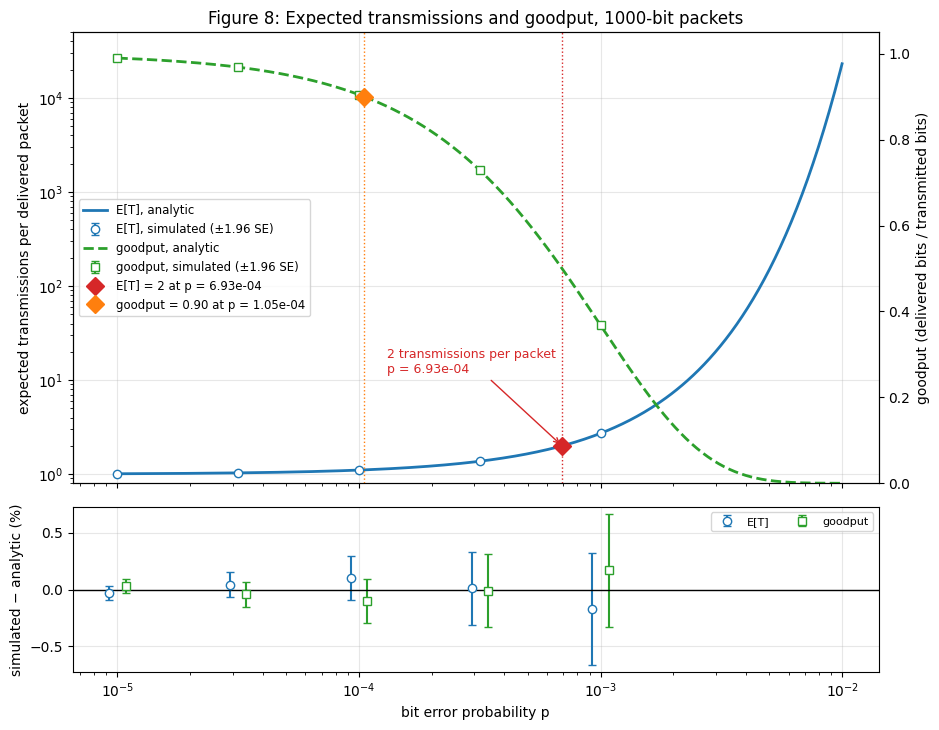

In [15]:
p_grid = np.logspace(-5, -2, 400)     # p values for the analytic curves

fig, (ax, ax_resid) = plt.subplots(2, 1, figsize=(9.5, 7.4), sharex=True,
                                   gridspec_kw={"height_ratios": [3, 1.1]})
ax_gp = ax.twinx()                    # right-hand axis for goodput

# Expected transmissions (left axis, log scale)
tx_line, = ax.plot(p_grid, expected_tx(p_grid), color="C0", lw=2, label="E[T], analytic")
tx_points = ax.errorbar(p_sim, tx_sim, yerr=Z95 * tx_se, fmt="o", mfc="white", color="C0",
                        capsize=3, label="E[T], simulated (±1.96 SE)")
tx_mark, = ax.plot(p_two_tx, 2, "D", color="C3", ms=9, zorder=5,
                   label=f"E[T] = 2 at p = {p_two_tx:.2e}")
ax.axvline(p_two_tx, color="C3", ls=":", lw=1)
ax.annotate(f"2 transmissions per packet\np = {p_two_tx:.2e}", xy=(p_two_tx, 2), xytext=(1.3e-4, 12),
            color="C3", fontsize=9, arrowprops={"arrowstyle": "->", "color": "C3"})

# Goodput (right axis, linear scale)
gp_line, = ax_gp.plot(p_grid, goodput(p_grid), color="C2", lw=2, ls="--", label="goodput, analytic")
gp_points = ax_gp.errorbar(p_sim, gp_sim, yerr=Z95 * gp_se, fmt="s", mfc="white", color="C2",
                           capsize=3, label="goodput, simulated (±1.96 SE)")
gp_mark, = ax_gp.plot(p_90, 0.9, "D", color="C1", ms=9, zorder=5,
                      label=f"goodput = 0.90 at p = {p_90:.2e}")
ax_gp.axvline(p_90, color="C1", ls=":", lw=1)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylim(0.8, 5e4)
ax_gp.set_ylim(0, 1.05)
ax_gp.grid(False)
ax.set_ylabel("expected transmissions per delivered packet")
ax_gp.set_ylabel("goodput (delivered bits / transmitted bits)")
ax.set_title("Figure 8: Expected transmissions and goodput, 1000-bit packets")
ax_gp.legend(handles=[tx_line, tx_points, gp_line, gp_points, tx_mark, gp_mark],
             loc="center left", fontsize=8.5)

# Lower panel: simulated minus analytic, in percent, with 95% error bars
tx_exact, gp_exact = expected_tx(p_sim), goodput(p_sim)
ax_resid.errorbar(p_sim / 1.08, 100 * (tx_sim / tx_exact - 1), yerr=100 * Z95 * tx_se / tx_exact,
                  fmt="o", mfc="white", color="C0", capsize=3, label="E[T]")
ax_resid.errorbar(p_sim * 1.08, 100 * (gp_sim / gp_exact - 1), yerr=100 * Z95 * gp_se / gp_exact,
                  fmt="s", mfc="white", color="C2", capsize=3, label="goodput")
ax_resid.axhline(0, color="k", lw=1)
ax_resid.set_xlabel("bit error probability p")
ax_resid.set_ylabel("simulated − analytic (%)")
ax_resid.legend(fontsize=8, ncol=2, loc="upper right")

fig.tight_layout()
plt.show()

**What Figure 8 shows.** Expected transmissions stay near 1 while the expected number of bit errors per packet, $np$, is small, and then climb steeply. Because $E[T] = (1-p)^{-1000} \approx e^{1000p}$ grows exponentially in $p$, the curve bends upward like a wall on log-log axes instead of following a straight line. It crosses 2 transmissions at $p = 6.93\times10^{-4}$ (red diamond) and reaches about 23,000 at $p = 10^{-2}$. Goodput is the mirror image, $1/E[T]$: 0.99 at $10^{-5}$, 0.90 at $1.05\times10^{-4}$ (orange diamond) and 0.37 at $10^{-3}$.

The five simulated points sit on both curves, and the largest difference is 1.02 standard errors (tables above). On these axes the 95% error bars are smaller than the markers, since the relative standard errors are below 0.3%, so the lower panel shows the differences in percent.

**8.4 Why the curve can be trusted out to $10^{-2}$ without simulating there.** The formula follows exactly from the model's two assumptions (independent bit errors within a packet and independent attempts), neither of which depends on $p$ or involves an approximation that gets worse as $p$ grows, so once the simulations confirm it at small $p$ it holds at every $p$.

### 8.7 Effect of packet length

The table gives both thresholds for 100-, 1000- and 10000-bit packets. Figure 9 repeats Figure 8 for all three lengths, with five simulated points per length.

In [16]:
lengths = [100, 1000, 10000]

rows = []
for n in lengths:
    rows.append([f"{n:,}", f"{p_for_expected_tx(2, n):.3e}", f"{p_for_goodput(0.9, n):.3e}",
                 f"{n * p_for_goodput(0.9, n):.4f}"])
show_table(["packet length n (bits)", "p where E[T] = 2", "p where goodput = 0.90",
            "n × p (goodput = 0.90)"], rows)

# Simulated points for each length, and their agreement with the exact formula
sim9 = {n: simulate_link(p_sim, n, rng8) for n in lengths}
z_values = []
for n in lengths:
    tx, se, _, _ = sim9[n]
    z_values += list(np.abs(tx - expected_tx(p_sim, n)) / se)
report_largest_z(z_values)

| packet length n (bits) | p where E[T] = 2 | p where goodput = 0.90 | n × p (goodput = 0.90) |
|:---|---:|---:|---:|
| 100 | 6.908e-03 | 1.053e-03 | 0.1053 |
| 1,000 | 6.929e-04 | 1.054e-04 | 0.1054 |
| 10,000 | 6.931e-05 | 1.054e-05 | 0.1054 |

Largest |z| = 2.53  ->  all within 3 standard errors: True


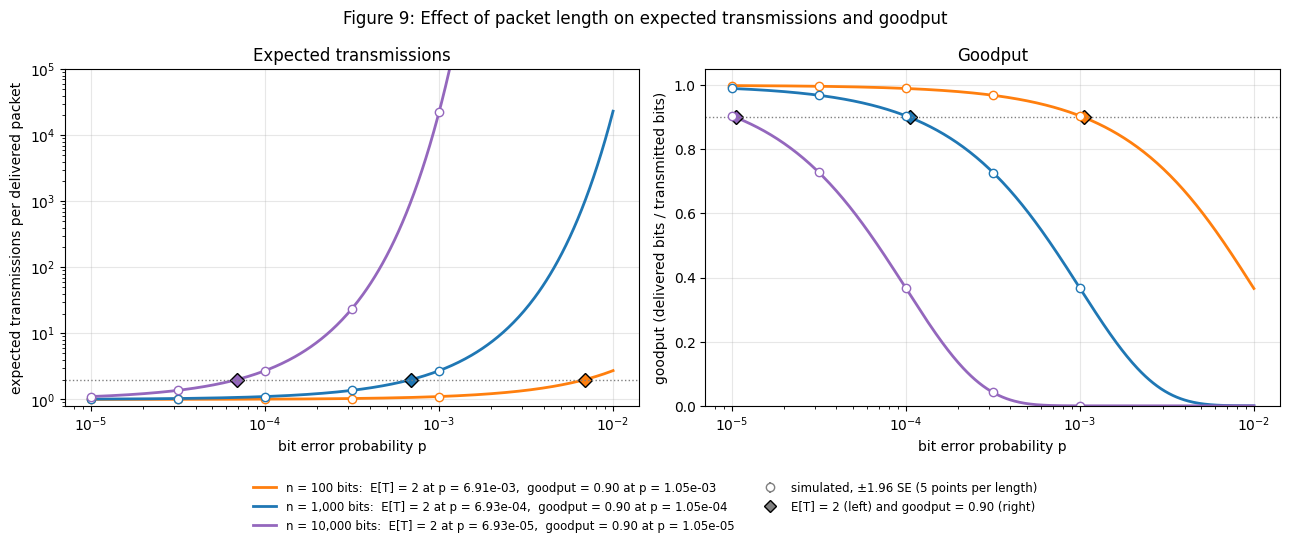

In [17]:
colors = {100: "C1", 1000: "C0", 10000: "C4"}

fig, (ax_tx, ax_gp) = plt.subplots(1, 2, figsize=(13, 5.4))
legend_handles = []
for n in lengths:
    color = colors[n]
    tx, tx_err, gp, gp_err = sim9[n]

    # Left panel: expected transmissions
    line, = ax_tx.plot(p_grid, expected_tx(p_grid, n), color=color, lw=2,
                       label=f"n = {n:,} bits:  E[T] = 2 at p = {p_for_expected_tx(2, n):.2e},  "
                             f"goodput = 0.90 at p = {p_for_goodput(0.9, n):.2e}")
    legend_handles.append(line)
    ax_tx.errorbar(p_sim, tx, yerr=Z95 * tx_err, fmt="o", mfc="white", color=color, capsize=2)
    ax_tx.plot(p_for_expected_tx(2, n), 2, "D", color=color, mec="k", ms=7)

    # Right panel: goodput
    ax_gp.plot(p_grid, goodput(p_grid, n), color=color, lw=2)
    ax_gp.errorbar(p_sim, gp, yerr=Z95 * gp_err, fmt="o", mfc="white", color=color, capsize=2)
    ax_gp.plot(p_for_goodput(0.9, n), 0.9, "D", color=color, mec="k", ms=7)

# Reference lines, plus gray legend entries for the two marker types
ax_tx.axhline(2, color="gray", ls=":", lw=1)
ax_gp.axhline(0.9, color="gray", ls=":", lw=1)
legend_handles.append(ax_tx.errorbar([], [], yerr=[], fmt="o", mfc="white", color="gray", capsize=2,
                                     label="simulated, ±1.96 SE (5 points per length)"))
legend_handles.append(ax_tx.plot([], [], "D", color="gray", mec="k", ls="none",
                                 label="E[T] = 2 (left) and goodput = 0.90 (right)")[0])

ax_tx.set(xscale="log", yscale="log", ylim=(0.8, 1e5), title="Expected transmissions",
          xlabel="bit error probability p", ylabel="expected transmissions per delivered packet")
ax_gp.set(xscale="log", ylim=(0, 1.05), title="Goodput",
          xlabel="bit error probability p", ylabel="goodput (delivered bits / transmitted bits)")
fig.legend(handles=legend_handles, loc="lower center", ncol=2, fontsize=8.5, frameon=False)
fig.suptitle("Figure 9: Effect of packet length on expected transmissions and goodput")
fig.tight_layout(rect=[0, 0.13, 1, 1])
plt.show()

**What Figure 9 shows.** The three curves have the same shape and shift by one decade in $p$ for every factor of 10 in packet length. That happens because $E[T] = (1-p)^{-n} \approx e^{np}$ depends on $p$ almost entirely through $np$, the expected number of bit errors per packet, so the 90% goodput threshold lands at $np \approx -\ln 0.9 = 0.105$ for every length (last column of the table above). The 15 simulated points agree with the curves, with a largest difference of 2.53 standard errors.

**8.7 What the link needs.** With 1000-bit packets, the link must hold a bit error rate at or below about $1.05\times10^{-4}$ to keep goodput above 90%, which means averaging no more than 1.11 transmissions per delivered packet; past $6.9\times10^{-4}$ it averages more than two, and at $10^{-3}$ only 37% of the transmitted bits are useful. The tolerable bit error rate scales inversely with packet length, $p_{\max} \approx 0.105/n$, so 100-bit packets relax the requirement tenfold to about $1.05\times10^{-3}$, while 10000-bit packets tighten it tenfold to about $1.05\times10^{-5}$ (Figure 9). If the radio cannot hold $10^{-4}$, the levers are shorter packets or forward error correction (which raises the chance that a packet arrives clean), and 10000-bit packets only make sense on a link that holds $10^{-5}$ or better. Shorter packets are not free, though: each one carries a fixed header, so in practice the best packet length balances header overhead against the chance that a packet arrives clean.

## Summary of the check-yourself values (Steps 6–8)

Each check-yourself value from the project specification for Steps 6–8, next to the value this notebook computes. Step 7 has no check-yourself values. All are reproduced.

In [18]:
summary = [
    ["6", "mean 1.4286 at q = 0.7", f"{mean_exact:.4f}", f"{mean_sim:.4f}"],
    ["6", "variance 0.6122 at q = 0.7", f"{var_exact:.4f}", f"{var_sim:.4f}"],
    ["8", "2 expected transmissions at p = 6.9 × 10⁻⁴", f"{p_two_tx:.3e}", "–"],
    ["8", "goodput 90% at p = 1.05 × 10⁻⁴", f"{p_90:.3e}", "–"],
]
show_table(["step", "check-yourself value", "this notebook (exact)", "this notebook (simulated)"], summary)

| step | check-yourself value | this notebook (exact) | this notebook (simulated) |
|:---|---:|---:|---:|
| 6 | mean 1.4286 at q = 0.7 | 1.4286 | 1.4325 |
| 6 | variance 0.6122 at q = 0.7 | 0.6122 | 0.6238 |
| 8 | 2 expected transmissions at p = 6.9 × 10⁻⁴ | 6.929e-04 | – |
| 8 | goodput 90% at p = 1.05 × 10⁻⁴ | 1.054e-04 | – |

In [19]:
print(f"Total runtime: {time.perf_counter() - start_time:.1f} s")

Total runtime: 4.6 s
